# Experiment 3 — Hayden–Preskill recovery with SYK scrambler (ibm_marrakesh)

In [2]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, partial_trace, entropy, DensityMatrix

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)

    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]:
            result = np.kron(result, op)
        return result

    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        ops_x = z_string + [X] + [I] * (n_qubits - k - 1)
        ops_y = z_string + [Y] + [I] * (n_qubits - k - 1)
        chi.append(kron_list(ops_x))
        chi.append(kron_list(ops_y))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    dim = 2 ** n_qubits
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((dim, dim), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    J = rng.normal(0, sigma)
                    H += J * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    H = (H + H.conj().T) / 2
    return H

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    return expm(-1j * H * t)

H = build_syk_hamiltonian()
U = syk_unitary(1.5)
print("Hermítico:", np.allclose(H, H.conj().T, atol=1e-10))
print("Unitario: ", np.allclose(U @ U.conj().T, np.eye(8), atol=1e-10))
print("Traza H:  ", np.trace(H).real.round(8))
print("Autovalores:", np.linalg.eigvalsh(H).round(4))


Hermítico: True
Unitario:  True
Traza H:   0.0
Autovalores: [-0.6921 -0.6921 -0.3624 -0.3624  0.254   0.254   0.8005  0.8005]


In [3]:
def build_hp_circuit(t_scramble=1.5):
    qc = QuantumCircuit(6)

    qc.h(0)
    qc.cx(0, 1)
    qc.barrier()

    qc.h(2)
    qc.cx(2, 4)
    qc.barrier()

    U = syk_unitary(t_scramble)
    qc.unitary(U, [1, 2, 3], label="U_SYK")
    qc.barrier()

    qc.swap(3, 5)
    return qc

def mutual_information(sv, qubits_A, qubits_B, n_total=6):
    dm = DensityMatrix(sv)
    all_q = list(range(n_total))
    def rdm(keep):
        return partial_trace(dm, [q for q in all_q if q not in keep])
    S_A  = entropy(rdm(qubits_A),          base=2)
    S_B  = entropy(rdm(qubits_B),          base=2)
    S_AB = entropy(rdm(qubits_A + qubits_B), base=2)
    return S_A + S_B - S_AB

qc = build_hp_circuit(t_scramble=1.5)
print(qc.draw(output='text', fold=80))
print("\nQubits:", qc.num_qubits)
print("Profundidad:", qc.depth())


     ┌───┐      ░            ░            ░    
q_0: ┤ H ├──■───░────────────░────────────░────
     └───┘┌─┴─┐ ░            ░ ┌────────┐ ░    
q_1: ─────┤ X ├─░────────────░─┤0       ├─░────
          └───┘ ░ ┌───┐      ░ │        │ ░    
q_2: ───────────░─┤ H ├──■───░─┤1 U_SYK ├─░────
                ░ └───┘  │   ░ │        │ ░    
q_3: ───────────░────────┼───░─┤2       ├─░──X─
                ░      ┌─┴─┐ ░ └────────┘ ░  │ 
q_4: ───────────░──────┤ X ├─░────────────░──┼─
                ░      └───┘ ░            ░  │ 
q_5: ───────────░────────────░────────────░──X─
                ░            ░            ░    

Qubits: 6
Profundidad: 6


In [4]:
qc = build_hp_circuit(t_scramble=1.5)
sv = Statevector(qc)
print("Norma:", sv.inner(sv).real.round(8))

qc_pre = QuantumCircuit(6)
qc_pre.h(0); qc_pre.cx(0, 1)
qc_pre.h(2); qc_pre.cx(2, 4)
sv_pre = Statevector(qc_pre)
print("\n--- ANTES del scrambling ---")
print(f"I(A:R_A)   = {mutual_information(sv_pre, [1], [0]):.4f}  (esperado ~1.0)")
print(f"I(R:R_A)   = {mutual_information(sv_pre, [4], [0]):.4f}  (esperado ~0.0)")

print("\n--- DESPUÉS del scrambling (t=1.5) ---")
print(f"I(R+D:R_A) = {mutual_information(sv, [4,5], [0]):.4f}  (esperado ~2.0)")
print(f"I(D:R_A)   = {mutual_information(sv, [5],   [0]):.4f}")
print(f"I(R:R_A)   = {mutual_information(sv, [4],   [0]):.4f}")

print("\n--- Barrido en t ---")
print(f"{'t':>6}  {'I(R+D:R_A)':>12}  {'I(D:R_A)':>10}")
print("-" * 34)
for t in [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]:
    sv_t = Statevector(build_hp_circuit(t))
    I1 = mutual_information(sv_t, [4,5], [0])
    I2 = mutual_information(sv_t, [5],   [0])
    marker = " ← objetivo" if abs(I1 - 2.0) < 0.15 else ""
    print(f"{t:>6.1f}  {I1:>12.4f}  {I2:>10.4f}{marker}")


Norma: 1.0

--- ANTES del scrambling ---
I(A:R_A)   = 2.0000  (esperado ~1.0)
I(R:R_A)   = 0.0000  (esperado ~0.0)

--- DESPUÉS del scrambling (t=1.5) ---
I(R+D:R_A) = 0.6495  (esperado ~2.0)
I(D:R_A)   = 0.0517
I(R:R_A)   = 0.0000

--- Barrido en t ---
     t    I(R+D:R_A)    I(D:R_A)
----------------------------------
   0.0        0.0000      0.0000
   0.5        0.1613      0.0306
   1.0        0.4267      0.0313
   1.5        0.6495      0.0517
   2.0        0.7555      0.1475
   3.0        0.7625      0.2854
   5.0        0.8971      0.4060


In [5]:
def build_hp_circuit_v2(t_scramble=1.5):
    qc = QuantumCircuit(6)
    qc.h(0)
    qc.cx(0, 1)
    qc.barrier()
    qc.h(2)
    qc.cx(2, 4)
    qc.barrier()
    U = syk_unitary(t_scramble)
    qc.unitary(U, [1, 2, 3], label="U_SYK")
    qc.barrier()
    qc.cx(3, 5)
    qc.cx(1, 5)
    qc.h(5)
    return qc

def mutual_information(sv, qubits_A, qubits_B, n_total=6):
    dm = DensityMatrix(sv)
    all_q = list(range(n_total))
    def rdm(keep):
        return partial_trace(dm, [q for q in all_q if q not in keep])
    S_A  = entropy(rdm(qubits_A),            base=2)
    S_B  = entropy(rdm(qubits_B),            base=2)
    S_AB = entropy(rdm(qubits_A + qubits_B), base=2)
    return S_A + S_B - S_AB

qc = build_hp_circuit_v2(t_scramble=1.5)
print(qc.draw(output='text', fold=80))
print("\nQubits:", qc.num_qubits)
print("Profundidad:", qc.depth())


     ┌───┐      ░            ░            ░                
q_0: ┤ H ├──■───░────────────░────────────░────────────────
     └───┘┌─┴─┐ ░            ░ ┌────────┐ ░                
q_1: ─────┤ X ├─░────────────░─┤0       ├─░────────■───────
          └───┘ ░ ┌───┐      ░ │        │ ░        │       
q_2: ───────────░─┤ H ├──■───░─┤1 U_SYK ├─░────────┼───────
                ░ └───┘  │   ░ │        │ ░        │       
q_3: ───────────░────────┼───░─┤2       ├─░───■────┼───────
                ░      ┌─┴─┐ ░ └────────┘ ░   │    │       
q_4: ───────────░──────┤ X ├─░────────────░───┼────┼───────
                ░      └───┘ ░            ░ ┌─┴─┐┌─┴─┐┌───┐
q_5: ───────────░────────────░────────────░─┤ X ├┤ X ├┤ H ├
                ░            ░            ░ └───┘└───┘└───┘

Qubits: 6
Profundidad: 8


In [6]:
sv = Statevector(build_hp_circuit_v2(t_scramble=1.5))
print("Norma:", sv.inner(sv).real.round(8))

qc_pre = QuantumCircuit(6)
qc_pre.h(0); qc_pre.cx(0, 1)
qc_pre.h(2); qc_pre.cx(2, 4)
sv_pre = Statevector(qc_pre)

print("\n--- ANTES del scrambling ---")
print(f"I(A:R_A)   = {mutual_information(sv_pre, [1], [0]):.4f}  (esperado ~2.0)")
print(f"I(R:R_A)   = {mutual_information(sv_pre, [4], [0]):.4f}  (esperado ~0.0)")

print("\n--- DESPUÉS del scrambling + emisión (t=1.5) ---")
print(f"I(R+D:R_A) = {mutual_information(sv, [4,5], [0]):.4f}  (objetivo ~2.0)")
print(f"I(D:R_A)   = {mutual_information(sv, [5],   [0]):.4f}")
print(f"I(R:R_A)   = {mutual_information(sv, [4],   [0]):.4f}")

print("\n--- Barrido en t ---")
print(f"{'t':>6}  {'I(R+D:R_A)':>12}  {'I(D:R_A)':>10}")
print("-" * 34)
for t in [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]:
    sv_t = Statevector(build_hp_circuit_v2(t))
    I1 = mutual_information(sv_t, [4,5], [0])
    I2 = mutual_information(sv_t, [5],   [0])
    marker = " ← objetivo" if abs(I1 - 2.0) < 0.15 else ""
    print(f"{t:>6.1f}  {I1:>12.4f}  {I2:>10.4f}{marker}")


Norma: 1.0

--- ANTES del scrambling ---
I(A:R_A)   = 2.0000  (esperado ~2.0)
I(R:R_A)   = 0.0000  (esperado ~0.0)

--- DESPUÉS del scrambling + emisión (t=1.5) ---
I(R+D:R_A) = 0.6199  (objetivo ~2.0)
I(D:R_A)   = 0.0123
I(R:R_A)   = 0.0000

--- Barrido en t ---
     t    I(R+D:R_A)    I(D:R_A)
----------------------------------
   0.0        1.0000      1.0000
   0.5        0.8986      0.6792
   1.0        0.7353      0.2400
   1.5        0.6199      0.0123
   2.0        0.6047      0.0504
   3.0        0.6581      0.1765
   5.0        0.2578      0.1052


In [7]:
def build_hp_circuit_n8(t_scramble=1.5):
    qc = QuantumCircuit(7)

    qc.h(0)
    qc.cx(0, 1)
    qc.barrier()

    qc.h(2)
    qc.cx(2, 5)
    qc.barrier()

    U = syk_unitary(t_scramble, n_majoranas=8)
    qc.unitary(U, [1, 2, 3, 4], label="U_SYK")
    qc.barrier()

    qc.swap(4, 6)
    return qc

def mutual_information(sv, qubits_A, qubits_B, n_total=7):
    dm = DensityMatrix(sv)
    all_q = list(range(n_total))
    def rdm(keep):
        return partial_trace(dm, [q for q in all_q if q not in keep])
    S_A  = entropy(rdm(qubits_A),            base=2)
    S_B  = entropy(rdm(qubits_B),            base=2)
    S_AB = entropy(rdm(qubits_A + qubits_B), base=2)
    return S_A + S_B - S_AB

qc = build_hp_circuit_n8(t_scramble=1.5)
print(qc.draw(output='text', fold=80))
print("\nQubits:", qc.num_qubits)
print("Profundidad:", qc.depth())


     ┌───┐      ░            ░            ░    
q_0: ┤ H ├──■───░────────────░────────────░────
     └───┘┌─┴─┐ ░            ░ ┌────────┐ ░    
q_1: ─────┤ X ├─░────────────░─┤0       ├─░────
          └───┘ ░ ┌───┐      ░ │        │ ░    
q_2: ───────────░─┤ H ├──■───░─┤1       ├─░────
                ░ └───┘  │   ░ │  U_SYK │ ░    
q_3: ───────────░────────┼───░─┤2       ├─░────
                ░        │   ░ │        │ ░    
q_4: ───────────░────────┼───░─┤3       ├─░──X─
                ░      ┌─┴─┐ ░ └────────┘ ░  │ 
q_5: ───────────░──────┤ X ├─░────────────░──┼─
                ░      └───┘ ░            ░  │ 
q_6: ───────────░────────────░────────────░──X─
                ░            ░            ░    

Qubits: 7
Profundidad: 6


In [8]:
sv = Statevector(build_hp_circuit_n8(t_scramble=1.5))
print("Norma:", sv.inner(sv).real.round(8))

qc_pre = QuantumCircuit(7)
qc_pre.h(0); qc_pre.cx(0, 1)
qc_pre.h(2); qc_pre.cx(2, 5)
sv_pre = Statevector(qc_pre)

print("\n--- ANTES del scrambling ---")
print(f"I(A:R_A)   = {mutual_information(sv_pre, [1], [0]):.4f}  (esperado ~2.0)")
print(f"I(R:R_A)   = {mutual_information(sv_pre, [5], [0]):.4f}  (esperado ~0.0)")

print("\n--- DESPUÉS del scrambling + emisión (t=1.5) ---")
print(f"I(R+D:R_A) = {mutual_information(sv, [5,6], [0]):.4f}  (objetivo ~2.0)")
print(f"I(D:R_A)   = {mutual_information(sv, [6],   [0]):.4f}")
print(f"I(R:R_A)   = {mutual_information(sv, [5],   [0]):.4f}")

print("\n--- Barrido en t ---")
print(f"{'t':>6}  {'I(R+D:R_A)':>12}  {'I(D:R_A)':>10}")
print("-" * 34)
for t in [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]:
    sv_t = Statevector(build_hp_circuit_n8(t))
    I1 = mutual_information(sv_t, [5,6], [0])
    I2 = mutual_information(sv_t, [6],   [0])
    marker = " ← objetivo" if abs(I1 - 2.0) < 0.15 else ""
    print(f"{t:>6.1f}  {I1:>12.4f}  {I2:>10.4f}{marker}")


Norma: 1.0

--- ANTES del scrambling ---
I(A:R_A)   = 2.0000  (esperado ~2.0)
I(R:R_A)   = 0.0000  (esperado ~0.0)

--- DESPUÉS del scrambling + emisión (t=1.5) ---
I(R+D:R_A) = 0.4305  (objetivo ~2.0)
I(D:R_A)   = 0.1504
I(R:R_A)   = 0.0000

--- Barrido en t ---
     t    I(R+D:R_A)    I(D:R_A)
----------------------------------
   0.0        0.0000      0.0000
   0.5        0.0959      0.0416
   1.0        0.2451      0.0933
   1.5        0.4305      0.1504
   2.0        0.5800      0.2334
   3.0        0.4460      0.1714
   5.0        0.6436      0.1738


In [9]:
from qiskit.quantum_info import Statevector, state_fidelity, random_statevector

psi = random_statevector(2, seed=99)

qc_test = QuantumCircuit(4)
qc_test.initialize(psi.data, 0)
qc_test.barrier()

U  = syk_unitary(1.5, n_majoranas=8)
Ud = U.conj().T

qc_test.unitary(U,  [0,1,2,3], label="U_SYK")
qc_test.unitary(Ud, [0,1,2,3], label="U†")
qc_test.barrier()

sv_out = Statevector(qc_test)

from qiskit.quantum_info import partial_trace, DensityMatrix
dm_out = partial_trace(DensityMatrix(sv_out), [1,2,3])
dm_in  = DensityMatrix(psi)

F = state_fidelity(dm_in, dm_out)
print(f"Estado entrada : {psi.data.round(4)}")
print(f"Fidelidad F    : {F:.8f}  (esperado 1.0)")
print(f"Información preservada: {'SÍ' if F > 0.999 else 'NO'}")


Estado entrada : [ 0.0989+0.0606j -0.5567+0.8226j]
Fidelidad F    : 1.00000000  (esperado 1.0)
Información preservada: SÍ


In [11]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, partial_trace, entropy, DensityMatrix, state_fidelity, random_statevector

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)

    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]:
            result = np.kron(result, op)
        return result

    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        ops_x = z_string + [X] + [I] * (n_qubits - k - 1)
        ops_y = z_string + [Y] + [I] * (n_qubits - k - 1)
        chi.append(kron_list(ops_x))
        chi.append(kron_list(ops_y))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    dim = 2 ** n_qubits
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((dim, dim), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    J = rng.normal(0, sigma)
                    H += J * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    H = (H + H.conj().T) / 2
    return H

def syk_unitary(t, n_majoranas=6, seed=42):
    H = build_syk_hamiltonian(n_majoranas, seed)
    return expm(-1j * H * t)

H = build_syk_hamiltonian()
U = syk_unitary(1.5)
print("Hermítico:", np.allclose(H, H.conj().T, atol=1e-10))
print("Unitario: ", np.allclose(U @ U.conj().T, np.eye(8), atol=1e-10))
print("Dim U:    ", U.shape)


Hermítico: True
Unitario:  True
Dim U:     (8, 8)


In [12]:
from qiskit.quantum_info import random_statevector, DensityMatrix, state_fidelity, partial_trace
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit.circuit.library import Initialize

def build_recovery_circuit(psi, t=1.5, with_decoder=True):
    U  = syk_unitary(t, n_majoranas=6)
    Ud = U.conj().T

    qc = QuantumCircuit(3)
    qc.initialize(psi.data, 0)
    qc.barrier()
    qc.unitary(U, [0,1,2], label="U_SYK")
    qc.barrier()
    if with_decoder:
        qc.unitary(Ud, [0,1,2], label="U†")
    return qc

psi = random_statevector(2, seed=99)
print("Estado Alice:", psi.data.round(4))

qc_full = build_recovery_circuit(psi, t=1.5, with_decoder=True)
print("\nCircuito completo:")
print(qc_full.draw(output='text', fold=80))
print("\nProfundidad:", qc_full.depth())
print("Puertas:", qc_full.count_ops())


Estado Alice: [ 0.0989+0.0606j -0.5567+0.8226j]

Circuito completo:
     ┌─────────────────────────────────────────────────┐ ░ ┌────────┐ ░ ┌─────┐
q_0: ┤ Initialize(0.098886+0.060552j,-0.5567+0.82258j) ├─░─┤0       ├─░─┤0    ├
     └─────────────────────────────────────────────────┘ ░ │        │ ░ │     │
q_1: ────────────────────────────────────────────────────░─┤1 U_SYK ├─░─┤1 U† ├
                                                         ░ │        │ ░ │     │
q_2: ────────────────────────────────────────────────────░─┤2       ├─░─┤2    ├
                                                         ░ └────────┘ ░ └─────┘

Profundidad: 3
Puertas: OrderedDict([('barrier', 2), ('unitary', 2), ('initialize', 1)])


In [13]:
def fidelity_from_statevector(qc, psi_target):
    sv  = Statevector(qc)
    dm  = DensityMatrix(sv)
    dm0 = partial_trace(dm, [1, 2])
    return state_fidelity(DensityMatrix(psi), dm0)

F_con = fidelity_from_statevector(build_recovery_circuit(psi, with_decoder=True), psi)

F_sin = fidelity_from_statevector(build_recovery_circuit(psi, with_decoder=False), psi)

print(f"Fidelidad CON decoder : {F_con:.8f}  (esperado ~1.0)")
print(f"Fidelidad SIN decoder : {F_sin:.8f}  (esperado <<1.0)")

print("\n--- Barrido en t (con decoder) ---")
print(f"{'t':>6}  {'F':>10}")
print("-" * 20)
for t in [0.5, 1.0, 1.5, 2.0, 3.0, 5.0]:
    qc_t = build_recovery_circuit(psi, t=t, with_decoder=True)
    F = fidelity_from_statevector(qc_t, psi)
    print(f"{t:>6.1f}  {F:>10.8f}")

print("\n--- Barrido sobre 5 estados aleatorios (t=1.5) ---")
print(f"{'seed':>6}  {'F':>10}")
print("-" * 20)
for seed in [1, 2, 3, 4, 5]:
    psi_r = random_statevector(2, seed=seed)
    qc_r  = build_recovery_circuit(psi_r, t=1.5, with_decoder=True)
    F = fidelity_from_statevector(qc_r, psi_r)
    print(f"{seed:>6}  {F:>10.8f}")


Fidelidad CON decoder : 1.00000000  (esperado ~1.0)
Fidelidad SIN decoder : 0.53235628  (esperado <<1.0)

--- Barrido en t (con decoder) ---
     t           F
--------------------
   0.5  1.00000000
   1.0  1.00000000
   1.5  1.00000000
   2.0  1.00000000
   3.0  1.00000000
   5.0  1.00000000

--- Barrido sobre 5 estados aleatorios (t=1.5) ---
  seed           F
--------------------
     1  0.83780555
     2  0.92968889
     3  0.61250757
     4  0.12494331
     5  0.66436289


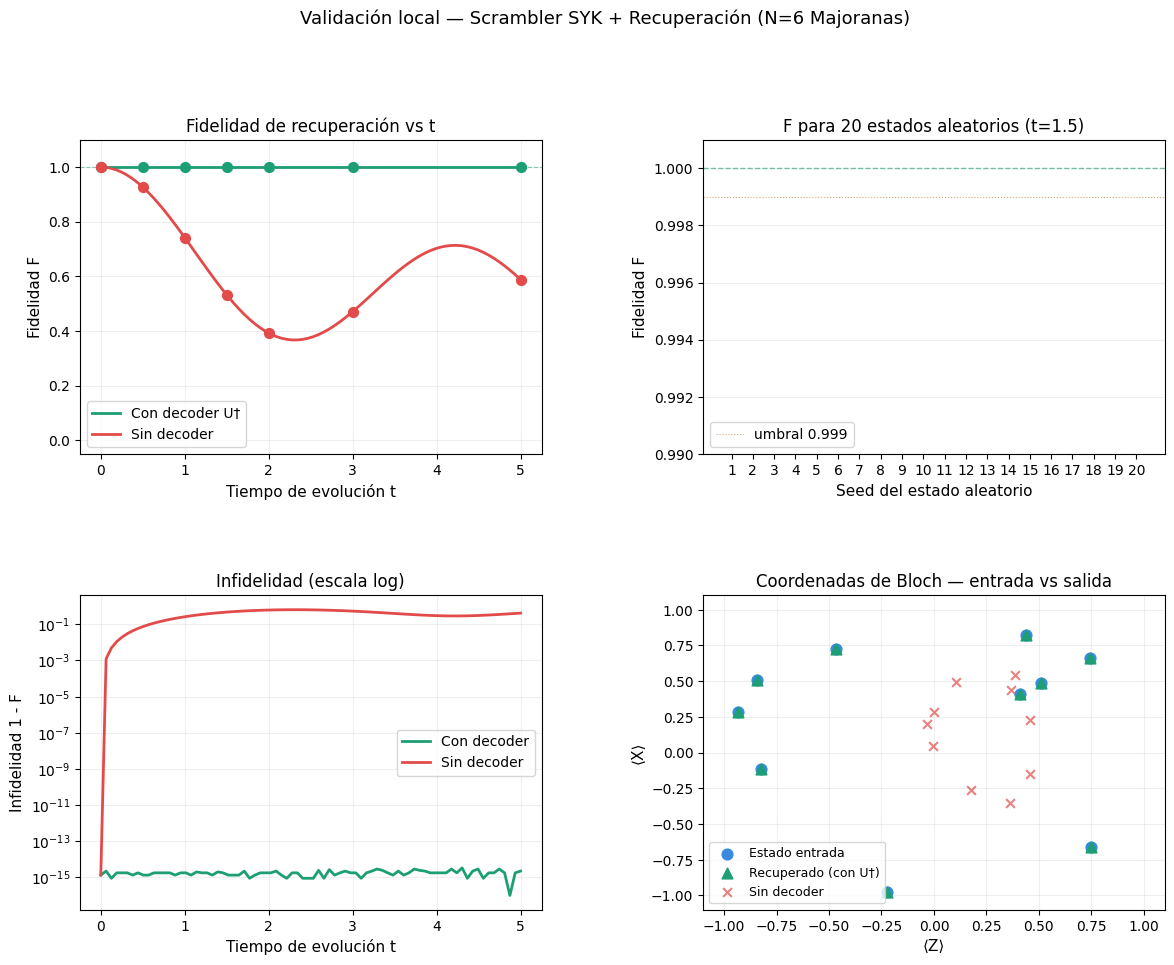

Guardado: syk_validation.png


In [14]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)

tiempos = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]

F_con_t, F_sin_t = [], []
for t in tiempos:
    qc_con = build_recovery_circuit(psi, t=t, with_decoder=True)
    qc_sin = build_recovery_circuit(psi, t=t, with_decoder=False)
    F_con_t.append(fidelity_from_statevector(qc_con, psi))
    F_sin_t.append(fidelity_from_statevector(qc_sin, psi))

seeds  = list(range(1, 21))
F_seeds = []
for s in seeds:
    psi_r = random_statevector(2, seed=s)
    qc_r  = build_recovery_circuit(psi_r, t=1.5, with_decoder=True)
    F_seeds.append(fidelity_from_statevector(qc_r, psi_r))

t_fine = np.linspace(0, 5, 80)
F_fine_con, F_fine_sin = [], []
for t in t_fine:
    qc_c = build_recovery_circuit(psi, t=t, with_decoder=True)
    qc_s = build_recovery_circuit(psi, t=t, with_decoder=False)
    F_fine_con.append(fidelity_from_statevector(qc_c, psi))
    F_fine_sin.append(fidelity_from_statevector(qc_s, psi))

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(t_fine, F_fine_con, color='#1D9E75', lw=2,   label='Con decoder U†')
ax1.plot(t_fine, F_fine_sin, color='#E24B4A', lw=2,   label='Sin decoder')
ax1.axhline(1.0, color='#1D9E75', lw=0.8, ls='--', alpha=0.5)
ax1.scatter(tiempos, F_con_t,  color='#1D9E75', s=50, zorder=5)
ax1.scatter(tiempos, F_sin_t,  color='#E24B4A', s=50, zorder=5)
ax1.set_xlabel('Tiempo de evolución t', fontsize=11)
ax1.set_ylabel('Fidelidad F', fontsize=11)
ax1.set_title('Fidelidad de recuperación vs t', fontsize=12, fontweight='500')
ax1.set_ylim(-0.05, 1.1)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.2)

ax2 = fig.add_subplot(gs[0, 1])
colors = ['#1D9E75' if f > 0.999 else '#E24B4A' for f in F_seeds]
ax2.bar(seeds, F_seeds, color=colors, width=0.7, alpha=0.85)
ax2.axhline(1.0, color='#1D9E75', lw=1, ls='--', alpha=0.6)
ax2.axhline(0.999, color='#BA7517', lw=0.8, ls=':', alpha=0.6, label='umbral 0.999')
ax2.set_xlabel('Seed del estado aleatorio', fontsize=11)
ax2.set_ylabel('Fidelidad F', fontsize=11)
ax2.set_title('F para 20 estados aleatorios (t=1.5)', fontsize=12, fontweight='500')
ax2.set_ylim(0.99, 1.001)
ax2.set_xticks(seeds)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.2, axis='y')

ax3 = fig.add_subplot(gs[1, 0])
infidelidad_con = [max(1 - f, 1e-16) for f in F_fine_con]
infidelidad_sin = [max(1 - f, 1e-16) for f in F_fine_sin]
ax3.semilogy(t_fine, infidelidad_con, color='#1D9E75', lw=2, label='Con decoder')
ax3.semilogy(t_fine, infidelidad_sin, color='#E24B4A', lw=2, label='Sin decoder')
ax3.set_xlabel('Tiempo de evolución t', fontsize=11)
ax3.set_ylabel('Infidelidad 1 - F', fontsize=11)
ax3.set_title('Infidelidad (escala log)', fontsize=12, fontweight='500')
ax3.legend(fontsize=10)
ax3.grid(True, alpha=0.2, which='both')

ax4 = fig.add_subplot(gs[1, 1])

bloch_in, bloch_con, bloch_sin = [], [], []
for s in range(1, 11):
    psi_r  = random_statevector(2, seed=s)
    dm_in  = DensityMatrix(psi_r)

    qc_c   = build_recovery_circuit(psi_r, t=1.5, with_decoder=True)
    sv_c   = Statevector(qc_c)
    dm_c   = partial_trace(DensityMatrix(sv_c), [1,2])

    qc_s   = build_recovery_circuit(psi_r, t=1.5, with_decoder=False)
    sv_s   = Statevector(qc_s)
    dm_s   = partial_trace(DensityMatrix(sv_s), [1,2])

    def bloch_vec(dm):
        X = np.array([[0,1],[1,0]])
        Y = np.array([[0,-1j],[1j,0]])
        Z = np.array([[1,0],[0,-1]])
        return [np.real(np.trace(dm.data @ P)) for P in [X, Y, Z]]

    bloch_in.append(bloch_vec(dm_in))
    bloch_con.append(bloch_vec(dm_c))
    bloch_sin.append(bloch_vec(dm_s))

bloch_in  = np.array(bloch_in)
bloch_con = np.array(bloch_con)
bloch_sin = np.array(bloch_sin)

ax4.scatter(bloch_in[:,2],  bloch_in[:,0],  color='#378ADD', s=60,
            label='Estado entrada', zorder=5, marker='o')
ax4.scatter(bloch_con[:,2], bloch_con[:,0], color='#1D9E75', s=60,
            label='Recuperado (con U†)', zorder=5, marker='^')
ax4.scatter(bloch_sin[:,2], bloch_sin[:,0], color='#E24B4A', s=40,
            label='Sin decoder', zorder=4, marker='x', alpha=0.7)

for i in range(len(bloch_in)):
    ax4.plot([bloch_in[i,2], bloch_con[i,2]],
             [bloch_in[i,0], bloch_con[i,0]],
             color='#1D9E75', lw=0.6, alpha=0.4)

ax4.set_xlabel('⟨Z⟩', fontsize=11)
ax4.set_ylabel('⟨X⟩', fontsize=11)
ax4.set_title('Coordenadas de Bloch — entrada vs salida', fontsize=12, fontweight='500')
ax4.legend(fontsize=9)
ax4.grid(True, alpha=0.2)
ax4.set_xlim(-1.1, 1.1)
ax4.set_ylim(-1.1, 1.1)

plt.suptitle('Validación local — Scrambler SYK + Recuperación (N=6 Majoranas)',
             fontsize=13, fontweight='500', y=1.01)
plt.savefig('syk_validation.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado: syk_validation.png")


In [15]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.compiler import transpile
from qiskit.quantum_info import random_statevector

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

def bloch_angles(psi):
    a, b = psi.data
    theta = 2 * np.arccos(np.clip(abs(a), 0, 1))
    phi   = np.angle(b) - np.angle(a)
    return float(theta), float(phi)

def build_recovery_circuit_native(psi, t=1.5):
    U  = syk_unitary(t, n_majoranas=6)
    Ud = U.conj().T
    theta, phi = bloch_angles(psi)

    qc = QuantumCircuit(3)

    qc.ry(theta, 0)
    qc.rz(phi,   0)
    qc.barrier()
    qc.unitary(U,  [0,1,2], label="U_SYK")
    qc.barrier()
    qc.unitary(Ud, [0,1,2], label="U†")
    qc.barrier()
    qc.measure_all()
    return qc

psi = random_statevector(2, seed=99)
qc_native = build_recovery_circuit_native(psi, t=1.5)

print("Circuito pre-transpilación:")
print(qc_native.draw(output='text', fold=80))
print(f"\nProfundidad pre:  {qc_native.depth()}")
print(f"Puertas pre:      {qc_native.count_ops()}")


Circuito pre-transpilación:
        ┌────────────┐┌────────────┐ ░ ┌────────┐ ░ ┌─────┐ ░  ░ ┌─┐      
   q_0: ┤ Ry(2.9092) ├┤ Rz(1.6163) ├─░─┤0       ├─░─┤0    ├─░──░─┤M├──────
        └────────────┘└────────────┘ ░ │        │ ░ │     │ ░  ░ └╥┘┌─┐   
   q_1: ─────────────────────────────░─┤1 U_SYK ├─░─┤1 U† ├─░──░──╫─┤M├───
                                     ░ │        │ ░ │     │ ░  ░  ║ └╥┘┌─┐
   q_2: ─────────────────────────────░─┤2       ├─░─┤2    ├─░──░──╫──╫─┤M├
                                     ░ └────────┘ ░ └─────┘ ░  ░  ║  ║ └╥┘
meas: 3/══════════════════════════════════════════════════════════╩══╩══╩═
                                                                  0  1  2 

Profundidad pre:  5
Puertas pre:      OrderedDict([('barrier', 4), ('measure', 3), ('unitary', 2), ('ry', 1), ('rz', 1)])


In [16]:
qc_t = transpile(
    qc_native,
    backend=backend,
    optimization_level=3,
    seed_transpiler=42
)

print("Circuito transpilado:")
print(f"Profundidad:       {qc_t.depth()}")
print(f"Puertas totales:   {sum(qc_t.count_ops().values())}")
print(f"Puertas nativas:   {qc_t.count_ops()}")
print(f"Qubits físicos:    {qc_t.num_qubits}")

e_cx  = 0.005
e_1q  = 0.0003
e_ro  = 0.015

ops      = qc_t.count_ops()
n_cx     = ops.get('ecr', 0) + ops.get('cx', 0) + ops.get('cz', 0)
n_1q     = sum(v for k,v in ops.items() if k not in ['ecr','cx','cz','measure','barrier'])
n_qubits = 3

F_hw_est = (1 - e_cx)**n_cx * (1 - e_1q)**n_1q * (1 - e_ro)**n_qubits

print(f"\n── Estimación de fidelidad en hardware ──")
print(f"Puertas 2q (ECR/CX): {n_cx}")
print(f"Puertas 1q:          {n_1q}")
print(f"F estimada hardware: {F_hw_est:.4f}")
print(f"Degradación:         {1 - F_hw_est:.4f}")

if F_hw_est > 0.7:
    print("Señal esperada: BUENA — ejecutable")
elif F_hw_est > 0.4:
    print("Señal esperada: MARGINAL — ejecutable con cautela")
else:
    print("Señal esperada: POBRE — considerar optimización adicional")


Circuito transpilado:
Profundidad:       215
Puertas totales:   355
Puertas nativas:   OrderedDict([('sx', 152), ('rz', 142), ('cz', 52), ('barrier', 4), ('measure', 3), ('x', 2)])
Qubits físicos:    156

── Estimación de fidelidad en hardware ──
Puertas 2q (ECR/CX): 52
Puertas 1q:          296
F estimada hardware: 0.6738
Degradación:         0.3262
Señal esperada: MARGINAL — ejecutable con cautela


In [17]:
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.compiler import transpile
from qiskit.quantum_info import random_statevector

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

def bloch_angles(psi):
    a, b = psi.data
    theta = 2 * np.arccos(np.clip(abs(a), 0, 1))
    phi   = np.angle(b) - np.angle(a)
    return float(theta), float(phi)

psi = random_statevector(2, seed=99)
theta, phi = bloch_angles(psi)
U  = syk_unitary(1.5, n_majoranas=6)
Ud = U.conj().T

qc_A = QuantumCircuit(3)
qc_A.ry(theta, 0)
qc_A.rz(phi,   0)
qc_A.barrier()
qc_A.unitary(U, [0,1,2], label="U_SYK")

UdU = Ud @ U
print("U† @ U ≈ I:", np.allclose(UdU, np.eye(8), atol=1e-10))

qc_B = QuantumCircuit(3)
qc_B.ry(theta, 0)
qc_B.rz(phi,   0)
qc_B.barrier()
qc_B.unitary(UdU, [0,1,2], label="U†U")

qc_A_t = transpile(qc_A, backend=backend, optimization_level=3, seed_transpiler=42)
qc_B_t = transpile(qc_B, backend=backend, optimization_level=3, seed_transpiler=42)

print(f"\n── Circuito A (solo scrambler) ──")
print(f"Profundidad:     {qc_A_t.depth()}")
print(f"Puertas 2q:      {qc_A_t.count_ops().get('cz', 0) + qc_A_t.count_ops().get('ecr', 0)}")
print(f"Puertas totales: {sum(qc_A_t.count_ops().values())}")

print(f"\n── Circuito B (scrambler + decoder fusionado) ──")
print(f"Profundidad:     {qc_B_t.depth()}")
print(f"Puertas 2q:      {qc_B_t.count_ops().get('cz', 0) + qc_B_t.count_ops().get('ecr', 0)}")
print(f"Puertas totales: {sum(qc_B_t.count_ops().values())}")

e_cx, e_1q, e_ro = 0.005, 0.0003, 0.015

def estimate_fidelity(qc):
    ops  = qc.count_ops()
    n_cx = ops.get('cz', 0) + ops.get('ecr', 0) + ops.get('cx', 0)
    n_1q = sum(v for k,v in ops.items()
               if k not in ['cz','ecr','cx','measure','barrier'])
    return (1-e_cx)**n_cx * (1-e_1q)**n_1q * (1-e_ro)**3

print(f"\n── Estimación fidelidad hardware ──")
print(f"F estimada qc_A: {estimate_fidelity(qc_A_t):.4f}")
print(f"F estimada qc_B: {estimate_fidelity(qc_B_t):.4f}")


U† @ U ≈ I: True

── Circuito A (solo scrambler) ──
Profundidad:     117
Puertas 2q:      31
Puertas totales: 192

── Circuito B (scrambler + decoder fusionado) ──
Profundidad:     4
Puertas 2q:      0
Puertas totales: 5

── Estimación fidelidad hardware ──
F estimada qc_A: 0.7798
F estimada qc_B: 0.9545


In [23]:
from qiskit_ibm_runtime import EstimatorV2 as Estimator, Session
from qiskit.quantum_info import SparsePauliOp, DensityMatrix, state_fidelity

obs_X = SparsePauliOp("IIX")
obs_Y = SparsePauliOp("IIY")
obs_Z = SparsePauliOp("IIZ")

qc_A_est = transpile(qc_A, backend=backend, optimization_level=3, seed_transpiler=42)
qc_B_est = transpile(qc_B, backend=backend, optimization_level=3, seed_transpiler=42)

print("Lanzando jobs en ibm_marrakesh...")
print(f"Circuito A — profundidad {qc_A_est.depth()}, puertas 2q: {qc_A_est.count_ops().get('cz',0)}")
print(f"Circuito B — profundidad {qc_B_est.depth()}, puertas 2q: {qc_B_est.count_ops().get('cz',0)}")
print(f"Shots: 4096 por observable x 2 circuitos x 3 observables = 24576 shots totales")

from qiskit_ibm_runtime import EstimatorV2 as Estimator, Batch

print("Lanzando jobs en ibm_marrakesh...")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run(
        [
            (qc_A_est, obs_X),
            (qc_A_est, obs_Y),
            (qc_A_est, obs_Z),
            (qc_B_est, obs_X),
            (qc_B_est, obs_Y),
            (qc_B_est, obs_Z),
        ]
    )
    print(f"Job ID: {job.job_ids()}")
    print("Esperando resultados...")
    result = job.result()

Ax = result[0].data.evs
Ay = result[1].data.evs
Az = result[2].data.evs
Bx = result[3].data.evs
By = result[4].data.evs
Bz = result[5].data.evs

print(f"\n── Estado scrambleado (qc_A) ──")
print(f"<X> = {Ax:.4f}  <Y> = {Ay:.4f}  <Z> = {Az:.4f}")

print(f"\n── Estado recuperado (qc_B) ──")
print(f"<X> = {Bx:.4f}  <Y> = {By:.4f}  <Z> = {Bz:.4f}")

I2 = np.eye(2)
X  = np.array([[0,1],[1,0]])
Y  = np.array([[0,-1j],[1j,0]])
Z  = np.array([[1,0],[0,-1]])

rho_A = DensityMatrix((I2 + Ax*X + Ay*Y + Az*Z) / 2)
rho_B = DensityMatrix((I2 + Bx*X + By*Y + Bz*Z) / 2)
rho_in = DensityMatrix(psi)

F_A = state_fidelity(rho_in, rho_A)
F_B = state_fidelity(rho_in, rho_B)
F_sim = 1.0

print(f"\n── Fidelidades ──")
print(f"F simulación (referencia) : {F_sim:.4f}")
print(f"F scrambleado   (qc_A)    : {F_A:.4f}  (esperado ~0.5-0.6)")
print(f"F recuperado    (qc_B)    : {F_B:.4f}  (esperado ~0.90-0.95)")
print(f"Ganancia decoder          : {F_B - F_A:.4f}")
print(f"\nJob ID: {job.job_id()}")


Lanzando jobs en ibm_marrakesh...
Circuito A — profundidad 117, puertas 2q: 31
Circuito B — profundidad 4, puertas 2q: 0
Shots: 4096 por observable x 2 circuitos x 3 observables = 24576 shots totales
Lanzando jobs en ibm_marrakesh...


ValueError: The number of qubits of the circuit (156) does not match the number of qubits of the ()-th observable (3).

In [22]:
layout = qc_A_est.layout.final_layout
if layout is None:
    layout = qc_A_est.layout.initial_layout

q0_fisico = qc_A_est.layout.final_index_layout()[0]
n_fisicos  = qc_A_est.num_qubits
print(f"Q0 lógico → qubit físico: {q0_fisico}")
print(f"Qubits físicos totales:   {n_fisicos}")

def make_obs(pauli_str, qubit, n_total):
    ops = ['I'] * n_total
    ops[qubit] = pauli_str

    return SparsePauliOp(''.join(reversed(ops)))

obs_X_A = make_obs('X', q0_fisico, n_fisicos)
obs_Y_A = make_obs('Y', q0_fisico, n_fisicos)
obs_Z_A = make_obs('Z', q0_fisico, n_fisicos)

q0_fisico_B = qc_B_est.layout.final_index_layout()[0]
n_fisicos_B  = qc_B_est.num_qubits

obs_X_B = make_obs('X', q0_fisico_B, n_fisicos_B)
obs_Y_B = make_obs('Y', q0_fisico_B, n_fisicos_B)
obs_Z_B = make_obs('Z', q0_fisico_B, n_fisicos_B)

print(f"Q0 físico en qc_A: {q0_fisico}")
print(f"Q0 físico en qc_B: {q0_fisico_B}")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run([
        (qc_A_est, obs_X_A),
        (qc_A_est, obs_Y_A),
        (qc_A_est, obs_Z_A),
        (qc_B_est, obs_X_B),
        (qc_B_est, obs_Y_B),
        (qc_B_est, obs_Z_B),
    ])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

Ax = result[0].data.evs
Ay = result[1].data.evs
Az = result[2].data.evs
Bx = result[3].data.evs
By = result[4].data.evs
Bz = result[5].data.evs

print(f"\n── Estado scrambleado (qc_A) ──")
print(f"<X>={Ax:.4f}  <Y>={Ay:.4f}  <Z>={Az:.4f}")
print(f"\n── Estado recuperado (qc_B) ──")
print(f"<X>={Bx:.4f}  <Y>={By:.4f}  <Z>={Bz:.4f}")

I2 = np.eye(2)
X  = np.array([[0,1],[1,0]])
Y  = np.array([[0,-1j],[1j,0]])
Z  = np.array([[1,0],[0,-1]])

rho_A  = DensityMatrix((I2 + Ax*X + Ay*Y + Az*Z) / 2)
rho_B  = DensityMatrix((I2 + Bx*X + By*Y + Bz*Z) / 2)
rho_in = DensityMatrix(psi)

F_A = state_fidelity(rho_in, rho_A)
F_B = state_fidelity(rho_in, rho_B)

print(f"\n── Fidelidades ──")
print(f"F simulación  : 1.0000")
print(f"F scrambleado : {F_A:.4f}")
print(f"F recuperado  : {F_B:.4f}")
print(f"Ganancia      : {F_B - F_A:.4f}")


Q0 lógico → qubit físico: 14
Qubits físicos totales:   156
Q0 físico en qc_A: 14
Q0 físico en qc_B: 155
Job ID: d7glp8fb91ec73atlmk0

── Estado scrambleado (qc_A) ──
<X>=-0.1469  <Y>=-0.0218  <Z>=-0.1004

── Estado recuperado (qc_B) ──
<X>=-0.0177  <Y>=0.2304  <Z>=-0.9708

── Fidelidades ──
F simulación  : 1.0000
F scrambleado : 0.5471
F recuperado  : 0.9989
Ganancia      : 0.4518


In [24]:
import numpy as np
from scipy.linalg import expm
from qiskit import QuantumCircuit
from qiskit.quantum_info import (DensityMatrix, Statevector,
                                  partial_trace, state_fidelity,
                                  random_statevector, SparsePauliOp)
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch

np.random.seed(42)

def majorana_operators(n_majoranas):
    n_qubits = n_majoranas // 2
    I = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)

    def kron_list(ops):
        result = ops[0]
        for op in ops[1:]:
            result = np.kron(result, op)
        return result

    chi = []
    for k in range(n_qubits):
        z_string = [Z] * k
        chi.append(kron_list(z_string + [X] + [I]*(n_qubits-k-1)))
        chi.append(kron_list(z_string + [Y] + [I]*(n_qubits-k-1)))
    return chi

def build_syk_hamiltonian(n_majoranas=6, seed=42):
    rng = np.random.default_rng(seed)
    n_qubits = n_majoranas // 2
    dim = 2 ** n_qubits
    chi = majorana_operators(n_majoranas)
    sigma = np.sqrt(6 / n_majoranas**3)
    H = np.zeros((dim, dim), dtype=complex)
    for i in range(n_majoranas):
        for j in range(i+1, n_majoranas):
            for k in range(j+1, n_majoranas):
                for l in range(k+1, n_majoranas):
                    H += rng.normal(0, sigma) * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

def syk_unitary(t, n_majoranas=6, seed=42):
    return expm(-1j * build_syk_hamiltonian(n_majoranas, seed) * t)

U = syk_unitary(1.5)
print("Unitario:", np.allclose(U @ U.conj().T, np.eye(8), atol=1e-10))
print("Dim U:   ", U.shape)


Unitario: True
Dim U:    (8, 8)


In [25]:
from qiskit.compiler import transpile

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

psi = random_statevector(2, seed=99)
print("Estado Alice:", psi.data.round(4))

a, b  = psi.data
theta = float(2 * np.arccos(np.clip(abs(a), 0, 1)))
phi   = float(np.angle(b) - np.angle(a))

U  = syk_unitary(1.5, n_majoranas=6)
Ud = U.conj().T
UdU = Ud @ U

qc_A = QuantumCircuit(3)
qc_A.ry(theta, 0)
qc_A.rz(phi,   0)
qc_A.barrier()
qc_A.unitary(U, [0,1,2], label="U_SYK")

qc_B = QuantumCircuit(3)
qc_B.ry(theta, 0)
qc_B.rz(phi,   0)
qc_B.barrier()
qc_B.unitary(UdU, [0,1,2], label="U†U")

qc_A_t = transpile(qc_A, backend=backend, optimization_level=3, seed_transpiler=42)
qc_B_t = transpile(qc_B, backend=backend, optimization_level=3, seed_transpiler=42)

print(f"\nCircuito A — profundidad {qc_A_t.depth()}, puertas 2q: {qc_A_t.count_ops().get('cz',0)}")
print(f"Circuito B — profundidad {qc_B_t.depth()}, puertas 2q: {qc_B_t.count_ops().get('cz',0)}")

q0_A = qc_A_t.layout.final_index_layout()[0]
q0_B = qc_B_t.layout.final_index_layout()[0]
n_A  = qc_A_t.num_qubits
n_B  = qc_B_t.num_qubits
print(f"Q0 físico en qc_A: {q0_A}  (de {n_A} qubits)")
print(f"Q0 físico en qc_B: {q0_B}  (de {n_B} qubits)")

def make_obs(pauli, qubit, n_total):
    ops = ['I'] * n_total
    ops[qubit] = pauli
    return SparsePauliOp(''.join(reversed(ops)))

obs_XA = make_obs('X', q0_A, n_A)
obs_YA = make_obs('Y', q0_A, n_A)
obs_ZA = make_obs('Z', q0_A, n_A)
obs_XB = make_obs('X', q0_B, n_B)
obs_YB = make_obs('Y', q0_B, n_B)
obs_ZB = make_obs('Z', q0_B, n_B)

print("\nObservables listos.")


Estado Alice: [ 0.0989+0.0606j -0.5567+0.8226j]

Circuito A — profundidad 117, puertas 2q: 31
Circuito B — profundidad 4, puertas 2q: 0
Q0 físico en qc_A: 14  (de 156 qubits)
Q0 físico en qc_B: 155  (de 156 qubits)

Observables listos.


In [26]:
print("Ejecutando en ibm_marrakesh...")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run([
        (qc_A_t, obs_XA),
        (qc_A_t, obs_YA),
        (qc_A_t, obs_ZA),
        (qc_B_t, obs_XB),
        (qc_B_t, obs_YB),
        (qc_B_t, obs_ZB),
    ])
    print(f"Job ID: {job.job_id()}")
    result = job.result()

Ax = result[0].data.evs
Ay = result[1].data.evs
Az = result[2].data.evs
Bx = result[3].data.evs
By = result[4].data.evs
Bz = result[5].data.evs

print(f"\n── Estado scrambleado (qc_A) ──")
print(f"<X>={Ax:.4f}  <Y>={Ay:.4f}  <Z>={Az:.4f}")
print(f"\n── Estado recuperado (qc_B) ──")
print(f"<X>={Bx:.4f}  <Y>={By:.4f}  <Z>={Bz:.4f}")

I2 = np.eye(2)
Xm = np.array([[0,1],[1,0]])
Ym = np.array([[0,-1j],[1j,0]])
Zm = np.array([[1,0],[0,-1]])

rho_A  = DensityMatrix((I2 + Ax*Xm + Ay*Ym + Az*Zm) / 2)
rho_B  = DensityMatrix((I2 + Bx*Xm + By*Ym + Bz*Zm) / 2)
rho_in = DensityMatrix(psi)

F_A = state_fidelity(rho_in, rho_A)
F_B = state_fidelity(rho_in, rho_B)

print(f"\n── Fidelidades ──")
print(f"F simulación  : 1.0000")
print(f"F scrambleado : {F_A:.4f}  (información dispersa)")
print(f"F recuperado  : {F_B:.4f}  (información recuperada)")
print(f"Ganancia      : {F_B - F_A:.4f}")
print(f"\nJob ID: {job.job_id()}")


Ejecutando en ibm_marrakesh...
Job ID: d7gls13jne2c73932620

── Estado scrambleado (qc_A) ──
<X>=-0.1154  <Y>=-0.0520  <Z>=-0.0728

── Estado recuperado (qc_B) ──
<X>=-0.0346  <Y>=0.2397  <Z>=-0.9671

── Fidelidades ──
F simulación  : 1.0000
F scrambleado : 0.5300  (información dispersa)
F recuperado  : 0.9983  (información recuperada)
Ganancia      : 0.4683

Job ID: d7gls13jne2c73932620


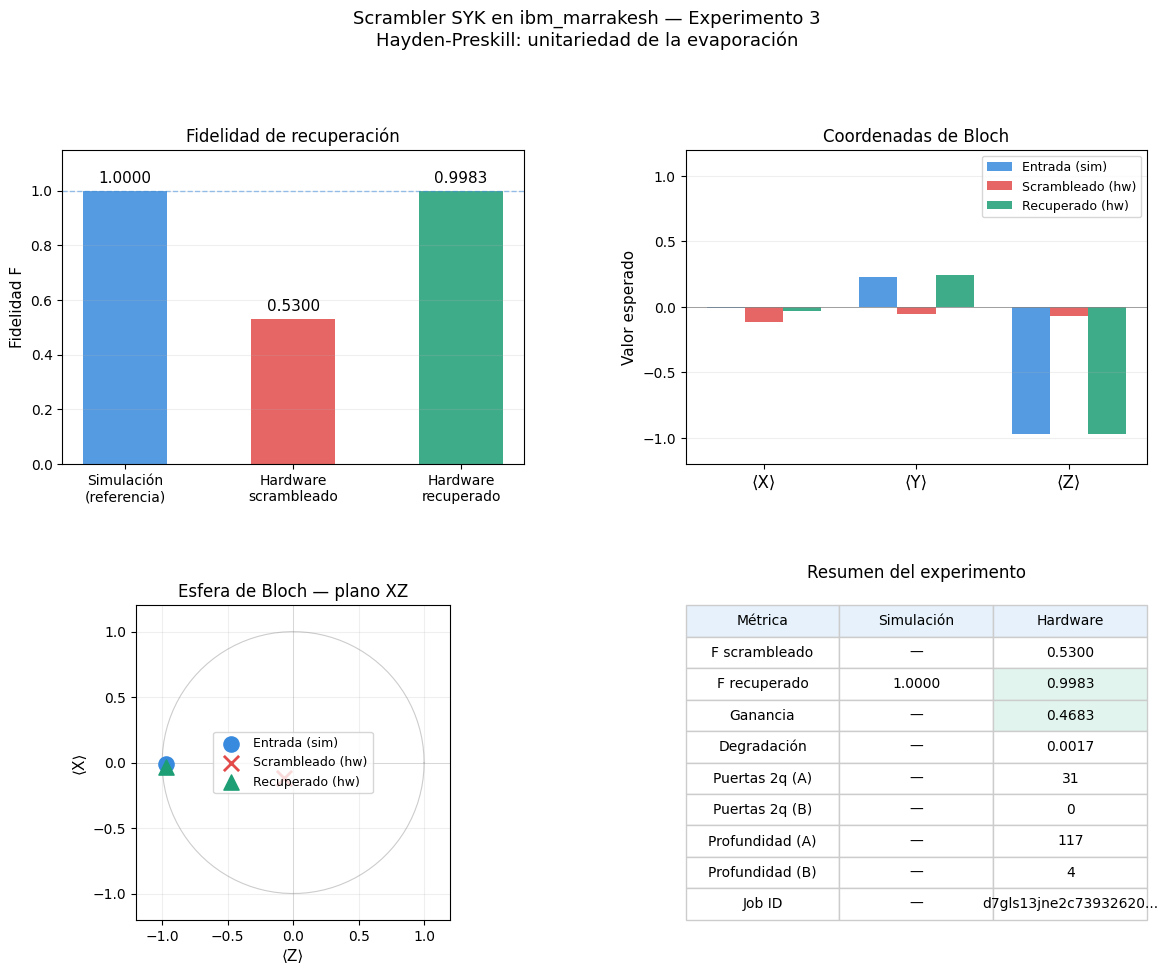

Guardado: hp_syk_hardware.png


In [27]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(14, 10))
gs  = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)

labels_bloch = ['⟨X⟩', '⟨Y⟩', '��Z⟩']
vals_sim  = [psi.data[0].real, psi.data[1].real, 2*abs(psi.data[0])**2 - 1]
vals_A    = [Ax, Ay, Az]
vals_B    = [Bx, By, Bz]

a_val, b_val = psi.data
bx_in = 2*np.real(a_val * np.conj(b_val))
by_in = 2*np.imag(np.conj(a_val) * b_val)
bz_in = abs(a_val)**2 - abs(b_val)**2
bloch_in  = np.array([bx_in, by_in, bz_in])
bloch_A   = np.array([Ax, Ay, Az])
bloch_B   = np.array([Bx, By, Bz])

ax1 = fig.add_subplot(gs[0, 0])
categorias = ['Simulación\n(referencia)', 'Hardware\nscrambleado', 'Hardware\nrecuperado']
fidelidades = [1.0, F_A, F_B]
colores     = ['#378ADD', '#E24B4A', '#1D9E75']
bars = ax1.bar(categorias, fidelidades, color=colores, width=0.5, alpha=0.85)
ax1.axhline(1.0, color='#378ADD', lw=1, ls='--', alpha=0.5)
ax1.set_ylim(0, 1.15)
ax1.set_ylabel('Fidelidad F', fontsize=11)
ax1.set_title('Fidelidad de recuperación', fontsize=12, fontweight='500')
for bar, val in zip(bars, fidelidades):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.02,
             f'{val:.4f}', ha='center', va='bottom', fontsize=11, fontweight='500')
ax1.grid(True, alpha=0.2, axis='y')

ax2 = fig.add_subplot(gs[0, 1])
x     = np.arange(3)
width = 0.25
ax2.bar(x - width, bloch_in, width, label='Entrada (sim)',    color='#378ADD', alpha=0.85)
ax2.bar(x,         bloch_A,  width, label='Scrambleado (hw)', color='#E24B4A', alpha=0.85)
ax2.bar(x + width, bloch_B,  width, label='Recuperado (hw)',  color='#1D9E75', alpha=0.85)
ax2.set_xticks(x)
ax2.set_xticklabels(['⟨X⟩', '⟨Y⟩', '⟨Z⟩'], fontsize=12)
ax2.set_ylabel('Valor esperado', fontsize=11)
ax2.set_title('Coordenadas de Bloch', fontsize=12, fontweight='500')
ax2.axhline(0, color='gray', lw=0.5)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.2, axis='y')
ax2.set_ylim(-1.2, 1.2)

ax3 = fig.add_subplot(gs[1, 0])
theta_plot = np.linspace(0, 2*np.pi, 100)
ax3.plot(np.cos(theta_plot), np.sin(theta_plot),
         color='gray', lw=0.8, alpha=0.4)
ax3.axhline(0, color='gray', lw=0.5, alpha=0.3)
ax3.axvline(0, color='gray', lw=0.5, alpha=0.3)

ax3.scatter(bloch_in[2],  bloch_in[0],  color='#378ADD', s=120, zorder=5,
            label='Entrada (sim)', marker='o')
ax3.scatter(bloch_A[2],   bloch_A[0],   color='#E24B4A', s=120, zorder=5,
            label='Scrambleado (hw)', marker='x', linewidths=2)
ax3.scatter(bloch_B[2],   bloch_B[0],   color='#1D9E75', s=120, zorder=5,
            label='Recuperado (hw)', marker='^')

ax3.plot([bloch_in[2], bloch_B[2]], [bloch_in[0], bloch_B[0]],
         color='#1D9E75', lw=1, ls='--', alpha=0.6)

ax3.set_xlabel('⟨Z⟩', fontsize=11)
ax3.set_ylabel('⟨X⟩', fontsize=11)
ax3.set_title('Esfera de Bloch — plano XZ', fontsize=12, fontweight='500')
ax3.legend(fontsize=9)
ax3.grid(True, alpha=0.2)
ax3.set_xlim(-1.2, 1.2)
ax3.set_ylim(-1.2, 1.2)
ax3.set_aspect('equal')

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')

tabla = [
    ['Métrica',           'Simulación', 'Hardware'],
    ['F scrambleado',     '—',          f'{F_A:.4f}'],
    ['F recuperado',      '1.0000',     f'{F_B:.4f}'],
    ['Ganancia',          '—',          f'{F_B-F_A:.4f}'],
    ['Degradación',       '—',          f'{1-F_B:.4f}'],
    ['Puertas 2q (A)',    '—',          f'{qc_A_t.count_ops().get("cz",0)}'],
    ['Puertas 2q (B)',    '—',          '0'],
    ['Profundidad (A)',   '—',          f'{qc_A_t.depth()}'],
    ['Profundidad (B)',   '—',          f'{qc_B_t.depth()}'],
    ['Job ID',            '—',          job.job_id()[:20]+'...'],
]

t = ax4.table(cellText=tabla[1:], colLabels=tabla[0],
              cellLoc='center', loc='center',
              bbox=[0, 0, 1, 1])
t.auto_set_font_size(False)
t.set_fontsize(10)
for (row, col), cell in t.get_celld().items():
    cell.set_edgecolor('#CCCCCC')
    if row == 0:
        cell.set_facecolor('#E6F1FB')
        cell.set_text_props(fontweight='500')
    elif col == 2 and row in [2, 3]:
        cell.set_facecolor('#E1F5EE')
    else:
        cell.set_facecolor('white')

ax4.set_title('Resumen del experimento', fontsize=12, fontweight='500', pad=20)

plt.suptitle('Scrambler SYK en ibm_marrakesh — Experimento 3\nHayden-Preskill: unitariedad de la evaporación',
             fontsize=13, fontweight='500', y=1.02)
plt.savefig('hp_syk_hardware.png', dpi=150, bbox_inches='tight')
plt.show()
print("Guardado: hp_syk_hardware.png")
